# Model comparison

Compares training fixes across all tracks using the shared `run_experiment` pipeline. Decisions here use training and validation data only. The test split stays locked until the final comparison (`evaluate_test=True`).

In [1]:
from pathlib import Path
import sys

import pandas as pd

# notebook is in training/benchmarking/notebooks, parents[1] points to training/
sys.path.insert(0, str(Path.cwd().parents[1]))

from benchmarking.data import NEWS_WITH_FEATURES, NO_NEWS_NO_FEATURES, NO_NEWS_WITH_FEATURES, TRACKS
from benchmarking.diagnostics import overfit_check
from benchmarking.experiment import ExperimentConfig, run_experiment
from benchmarking.fit_check import plot_experiment_training_fit, plot_saved_training_fit, plot_validation_fit
from benchmarking.metrics import summarize_seeds
from benchmarking.result_plots import plot_overfit_results, plot_seed_results

RESULTS_DIR = Path.cwd().parent / "results"
RESULTS_DIR.mkdir(exist_ok=True)

pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:.4f}".format)


def saved_predictions(prefix, track):
    """Read one track's saved predictions, so charts don't need retraining."""
    predictions = pd.read_csv(RESULTS_DIR / f"{prefix}_predictions.csv")
    return predictions[predictions["track"] == track]

## Phase 1a: can the models memorize a small training set?

Each model trains on 100 windows and is scored on those same windows, with the current unscaled inputs. 100 windows at 20 epochs is only 60 weight updates, so 1,000 epochs is included too. That's about 4,000 updates, similar to a full 20-epoch run on the no-news tracks.

- **R² near 1:** the setup can learn, so the full-data problem is weak signal or training settings.
- **R² far from 1, even at 1,000 epochs:** the setup itself is getting in the way.

In [2]:
overfit = pd.concat([overfit_check(track) for track in TRACKS], ignore_index=True)
overfit.to_csv(RESULTS_DIR / "phase1_overfit.csv", index=False)

overfit_summary = (
    overfit.assign(epochs=overfit["epochs"].astype("Int64").astype("string").fillna("control"))
    .groupby(["track", "model", "epochs"], sort=False)[["r2", "correlation", "spread_ratio"]]
    .agg(["mean", "min", "max"])
)
overfit_summary

r2                  correlation               spread_ratio              
                                                    mean      min     max        mean    min    max         mean    min    max
track                            model   epochs                                                                               
no_news_no_feature_engineering   RNN     20      -3.6675  -5.0017 -2.2398      0.0504 0.0066 0.1028       1.9411 1.5381 2.3394
                                         1000     0.9114   0.7511  0.9938      0.9781 0.9426 0.9971       1.0125 0.9784 1.0794
                                 LSTM    20       0.0209  -0.1821  0.1338      0.2502 0.0217 0.3951       0.4416 0.3552 0.5295
                                         1000     0.7604   0.6843  0.8990      0.9026 0.8673 0.9500       0.8968 0.8559 0.9189
                                 XGBoost control  0.9997   0.9997  0.9997      1.0000 1.0000 1.0000       0.9864 0.9864 0.9864
no_news_with_feature_engineering RNN     20      -4.4731 -10.3036 -1.3028      0.1244 0.0370 0.1739       2.0291 1.3147 3.2465
                                         1000     0.9773   0.9464  0.9985      0.9891 0.9737 0.9993       0.9723 0.9322 0.9934
                                 LSTM    20       0.0230  -0.1097  0.1092      0.2513 0.0943 0.3512       0.4405 0.4158 0.4690
                                         1000     0.8064   0.5826  0.9317      0.9351 0.8808 0.9668       0.8799 0.8259 0.9131
                                 XGBoost control  0.9998   0.9998  0.9998      1.0000 1.0000 1.0000       0.9871 0.9871 0.9871
news_with_feature_engineering    RNN     20      -2.8862  -6.1725 -0.5274      0.2082 0.0920 0.3907       1.7805 1.2153 2.5779
                                         1000     0.9998   0.9995  1.0000      0.9999 0.9998 1.0000       0.9983 0.9957 0.9998
                                 LSTM    20       0.1603   0.0693  0.2086      0.4054 0.3059 0.4582       0.4519 0.4427 0.4569
                                         1000     0.9977   0.9957  0.9997      0.9989 0.9979 0.9999       0.9939 0.9901 0.9979
                                 XGBoost control  0.9999   0.9999  0.9999      1.0000 1.0000 1.0000       0.9909 0.9909 0.9909

## Phase 1b: full training across 5 seeds

The notebook setups on full data, 1-day horizon. A real improvement should beat the baseline on validation across most seeds and be larger than the spread between seeds.

In [3]:
SEEDS = (42, 43, 44, 45, 46)

results = {
    track: run_experiment(ExperimentConfig(track=track, horizons=(1,), seeds=SEEDS))
    for track in TRACKS
}
metrics = pd.concat([result["metrics"] for result in results.values()], ignore_index=True)
metrics.to_csv(RESULTS_DIR / "phase1_seed_metrics.csv", index=False)

summary = summarize_seeds(metrics)
summary.to_csv(RESULTS_DIR / "phase1_seed_summary.csv", index=False)
summary.drop(columns=["horizon", "seeds"])

,track,model,split,r2_mean,r2_std,correlation_mean,correlation_std,spread_ratio_mean,spread_ratio_std,directional_accuracy_mean,directional_accuracy_std,always_up_accuracy,share_beating_baseline
0,no_news_no_feature_engineering,RNN,train,-0.0531,0.0407,0.1031,0.0194,0.3360,0.0596,0.5175,0.0116,0.5087,0.0000
1,no_news_no_feature_engineering,RNN,validation,-0.1436,0.0520,0.0035,0.0387,0.3707,0.0552,0.5017,0.0156,0.5300,0.0000
2,no_news_no_feature_engineering,LSTM,train,-0.0072,0.0123,0.0640,0.0238,0.1145,0.0548,0.5056,0.0082,0.5087,0.4000
3,no_news_no_feature_engineering,LSTM,validation,-0.0262,0.0227,0.0182,0.0387,0.1277,0.0572,0.4986,0.0142,0.5300,0.2000
4,no_news_no_feature_engineering,XGBoost,train,0.2594,0.0022,0.6375,0.0028,0.2542,0.0022,0.6009,0.0048,0.5087,1.0000
5,no_news_no_feature_engineering,XGBoost,validation,-0.0225,0.0034,-0.0346,0.0113,0.1172,0.0032,0.4992,0.0098,0.5300,0.0000
6,no_news_with_feature_engineering,RNN,train,-0.1006,0.0535,0.1200,0.0258,0.4096,0.0872,0.5145,0.0126,0.5094,0.0000
7,no_news_with_feature_engineering,RNN,validation,-0.2323,0.0989,0.0165,0.0194,0.4541,0.1067,0.5077,0.0167,0.5262,0.0000
8,no_news_with_feature_engineering,LSTM,train,-0.0107,0.0348,0.0847,0.0389,0.1352,0.1108,0.5109,0.0079,0.5094,0.6000
9,no_news_with_feature_engineering,LSTM,validation,-0.0338,0.0517,0.0189,0.0221,0.1454,0.1252,0.5120,0.0162,0.5262,0.0000


### Training fit, first seed

no_news_no_feature_engineering


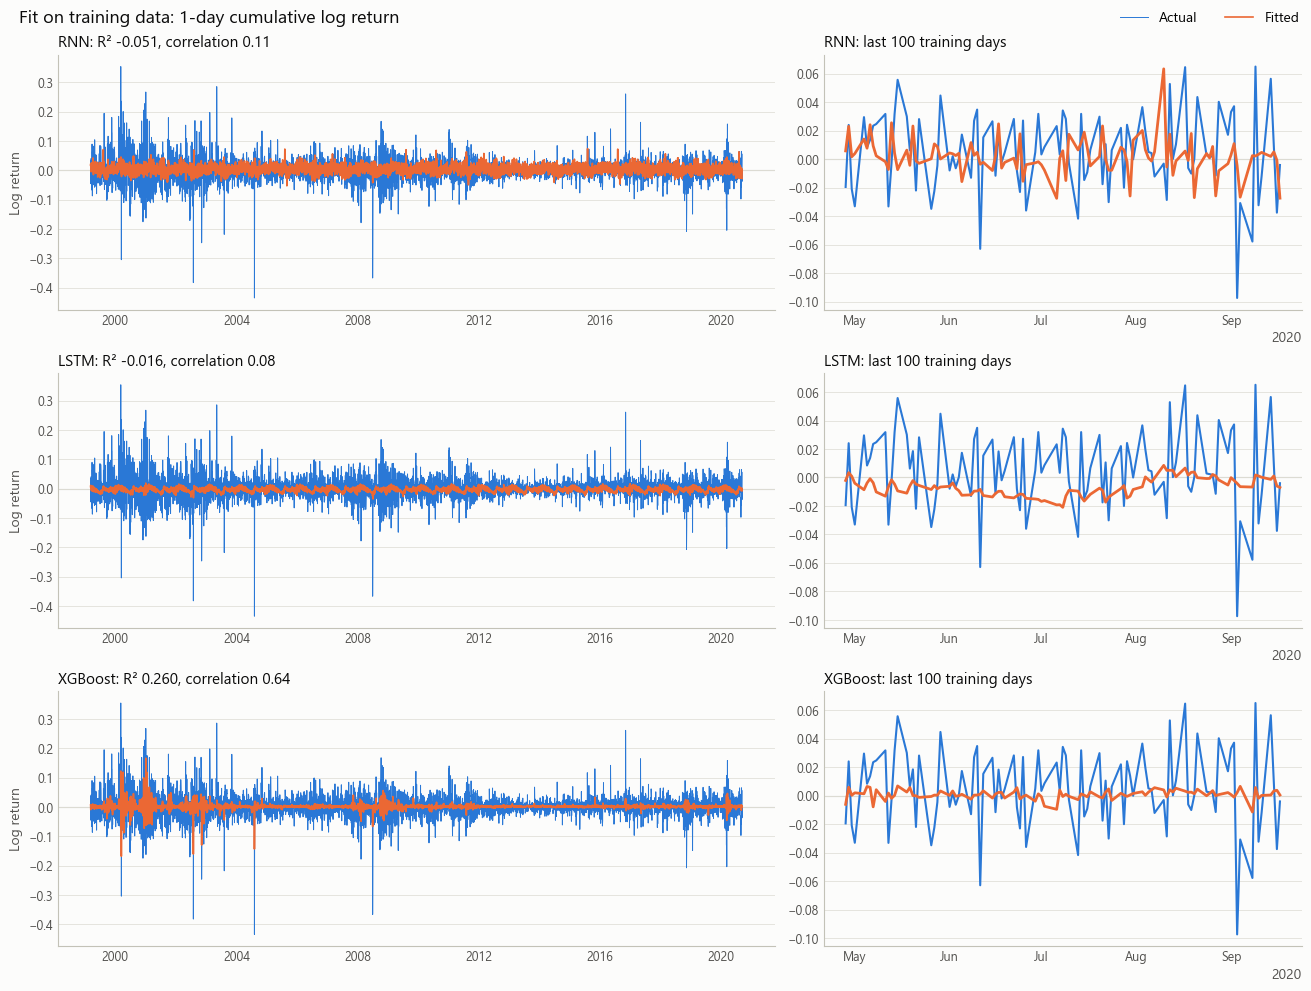

no_news_with_feature_engineering


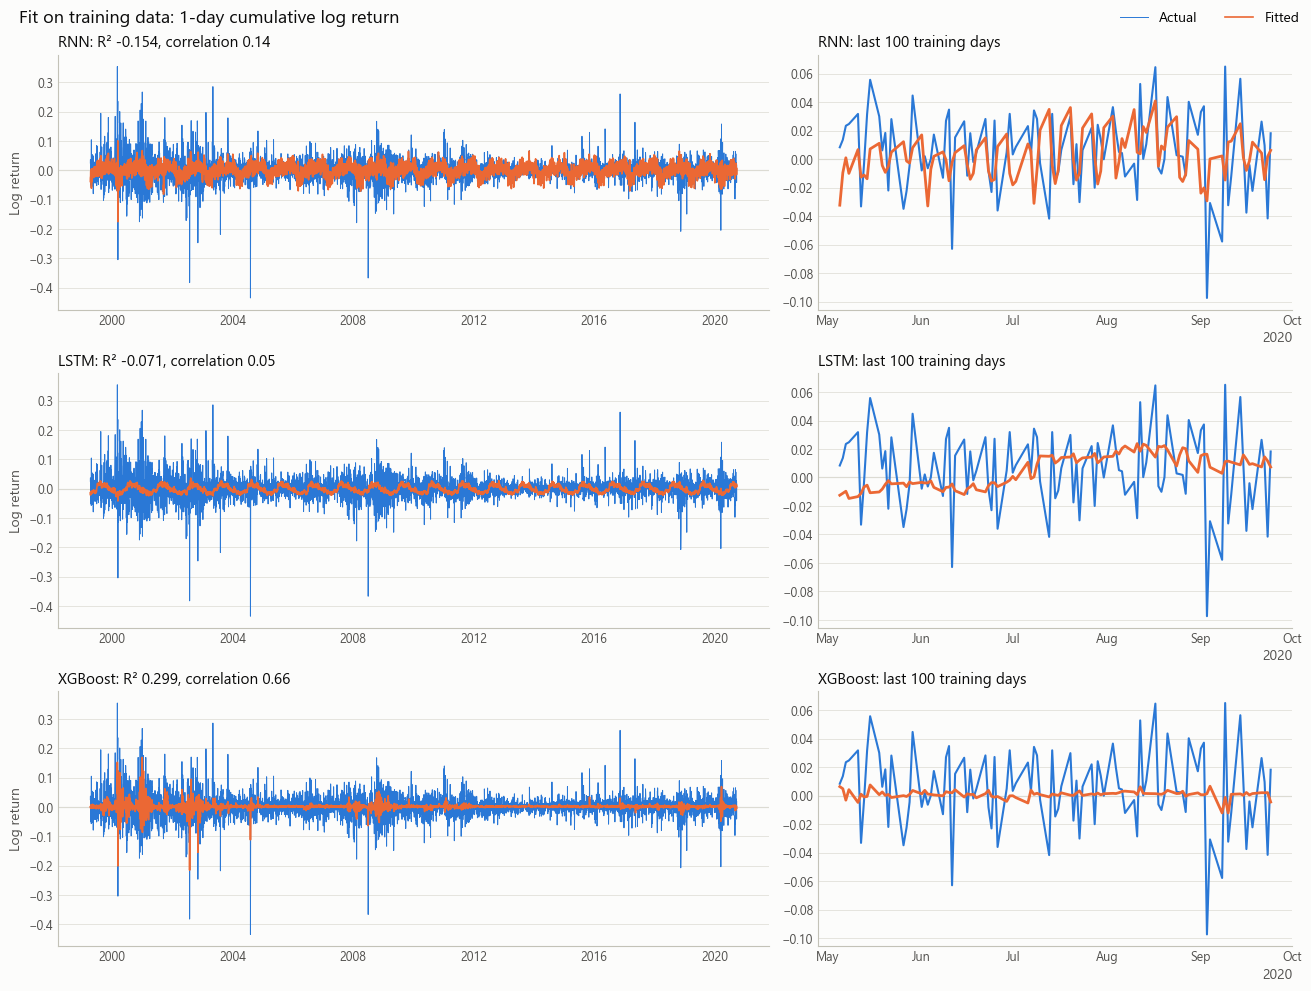

news_with_feature_engineering


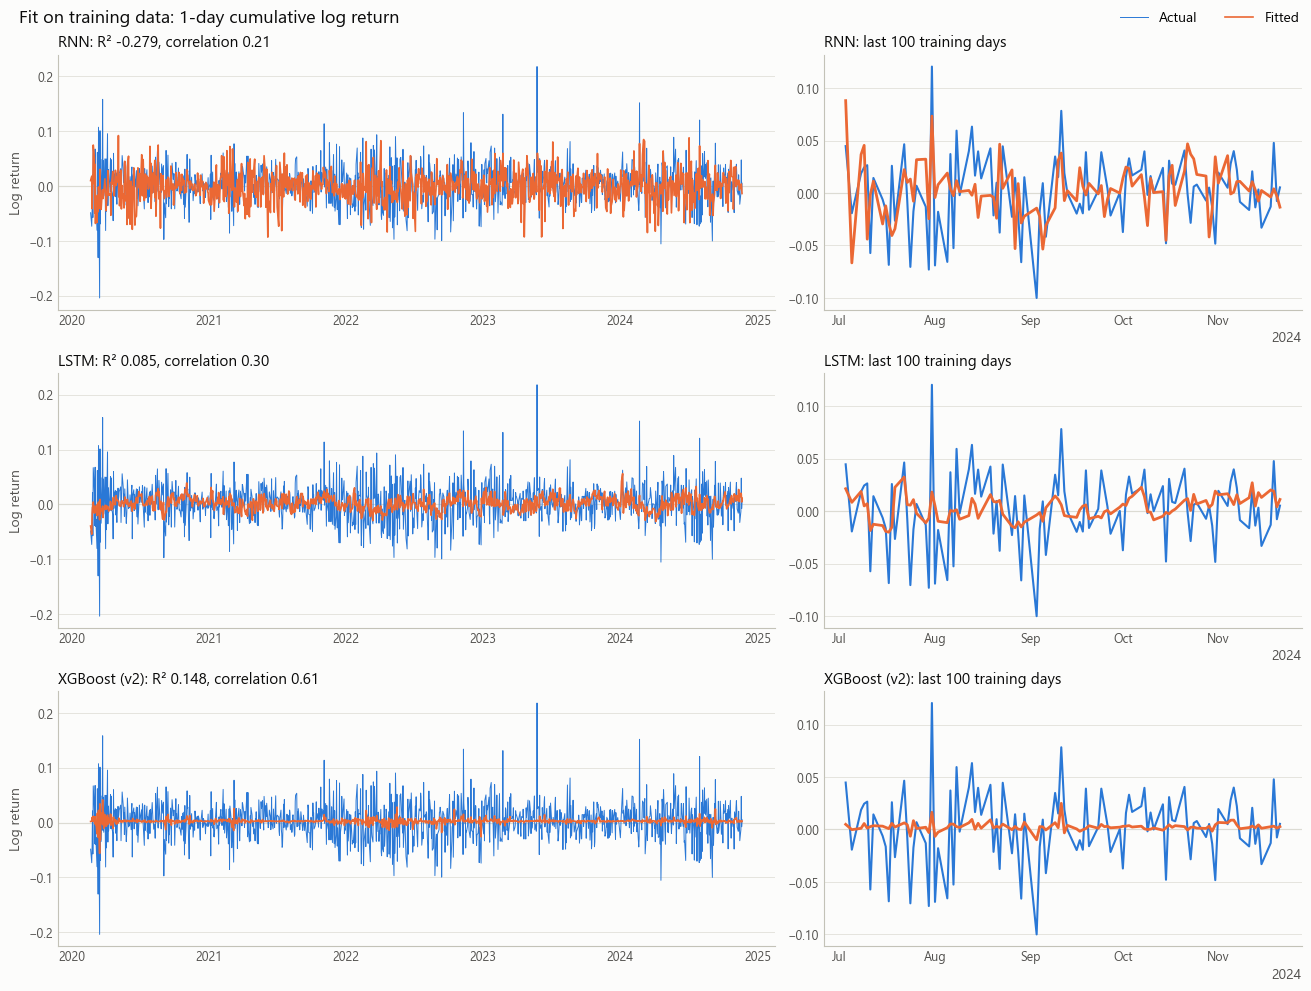

In [4]:
for track, result in results.items():
    print(track)
    plot_experiment_training_fit(result)

## Phase 1 results at a glance

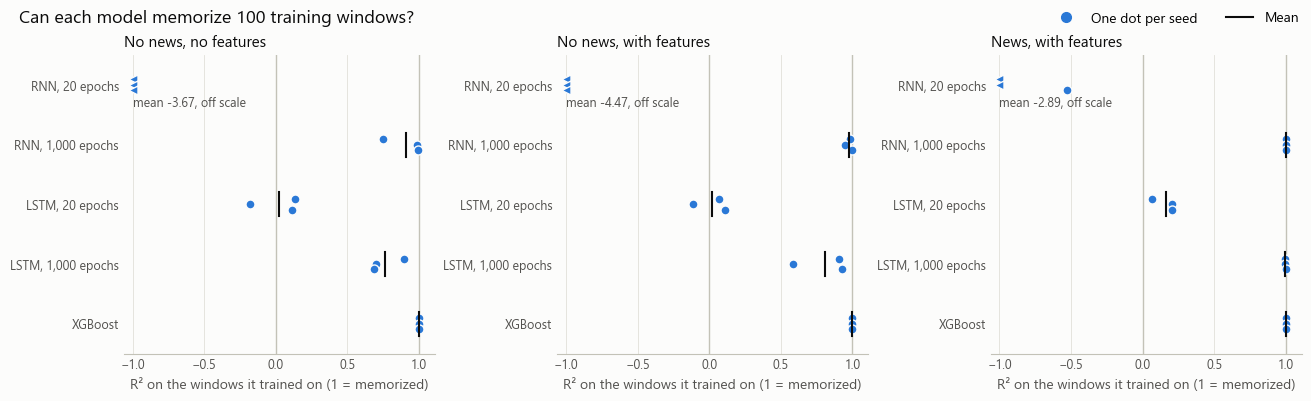

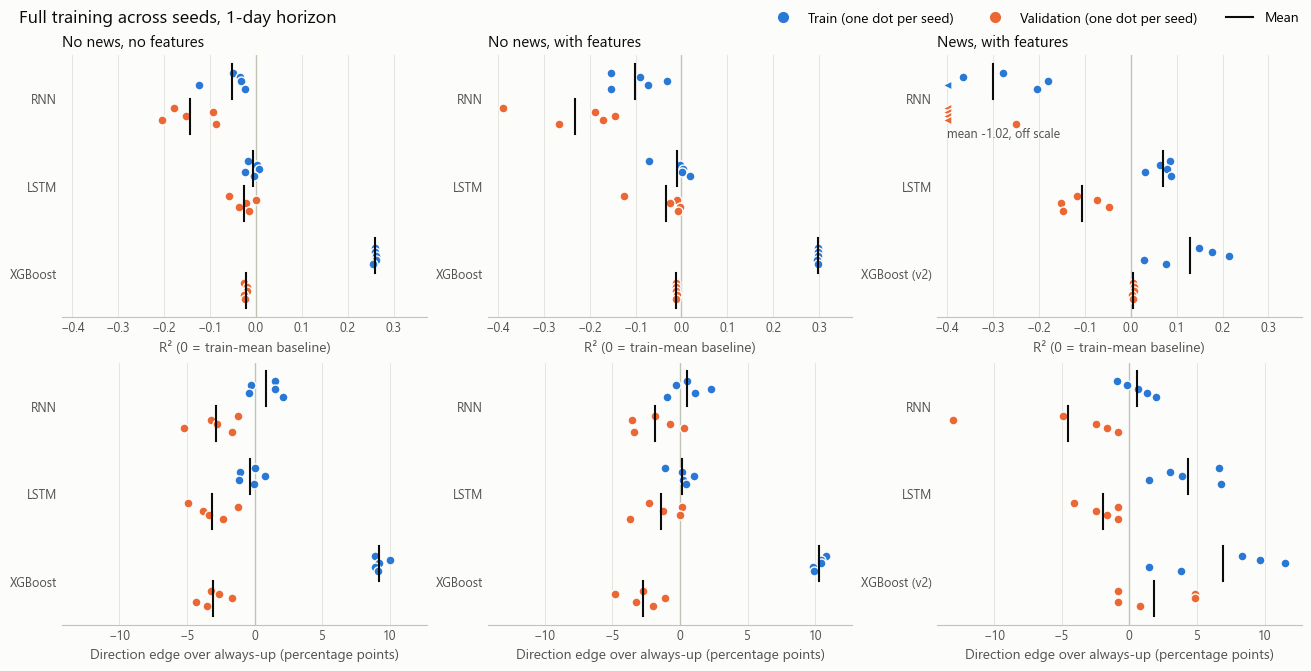

In [5]:
# Reads the saved results, so this cell doesn't retrain anything.
from benchmarking.result_plots import plot_overfit_results, plot_seed_results

plot_overfit_results(pd.read_csv(RESULTS_DIR / "phase1_overfit.csv"))
plot_seed_results(pd.read_csv(RESULTS_DIR / "phase1_seed_metrics.csv"))

## Phase 1 on common dates

Phase 1 again, with every track limited to the news track's dates (2020-01-08 to 2026-02-18). All tracks now share the same splits and targets, with 1,198 train and 123 validation windows, at the 1-day horizon.

The original Phase 1 above stays as the record of the no-news tracks on their full history. The news track's data doesn't change, so its results should match.

The next cell trains the models and saves the results. The chart cells after it read those files, so they can be rerun on their own.

In [6]:
def run_phase(prefix, **options):
    """Run the memorization test and full training, then save the results."""
    overfit = pd.concat([overfit_check(track, **options) for track in TRACKS], ignore_index=True)
    overfit.to_csv(RESULTS_DIR / f"{prefix}_overfit.csv", index=False)

    results = {
        track: run_experiment(ExperimentConfig(track=track, horizons=(1,), seeds=SEEDS, **options))
        for track in TRACKS
    }
    metrics = pd.concat([result["metrics"] for result in results.values()], ignore_index=True)
    metrics.to_csv(RESULTS_DIR / f"{prefix}_seed_metrics.csv", index=False)
    summarize_seeds(metrics).to_csv(RESULTS_DIR / f"{prefix}_seed_summary.csv", index=False)
    pd.concat([result["predictions"] for result in results.values()], ignore_index=True).to_csv(
        RESULTS_DIR / f"{prefix}_predictions.csv", index=False
    )
    return overfit, results, metrics


SEEDS = (42, 43, 44, 45, 46)
common_overfit, common_results, common_metrics = run_phase("phase1_common_dates", common_dates=True)

### Common dates: can each model memorize 100 windows?

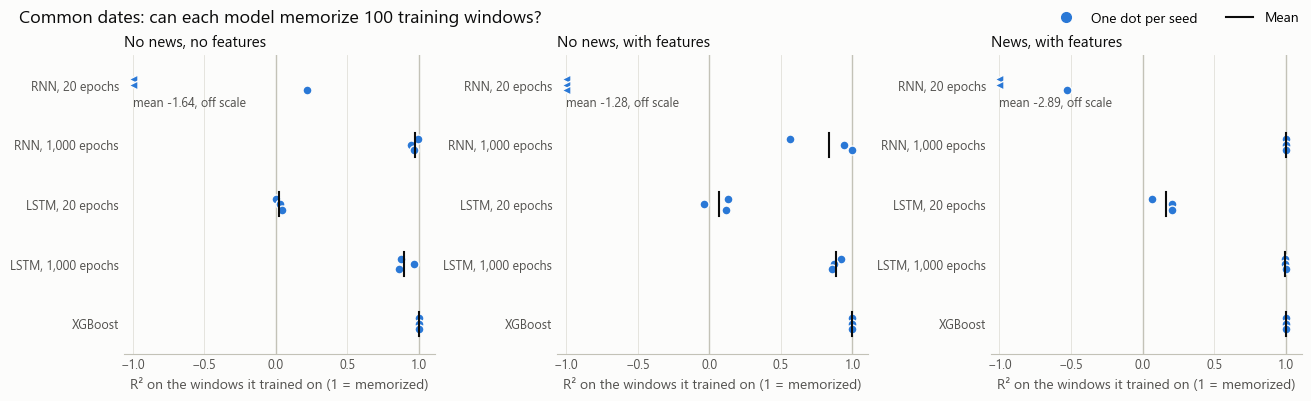

In [7]:
plot_overfit_results(
    pd.read_csv(RESULTS_DIR / "phase1_common_dates_overfit.csv"),
    title="Common dates: can each model memorize 100 training windows?",
)

### Common dates: full training across seeds

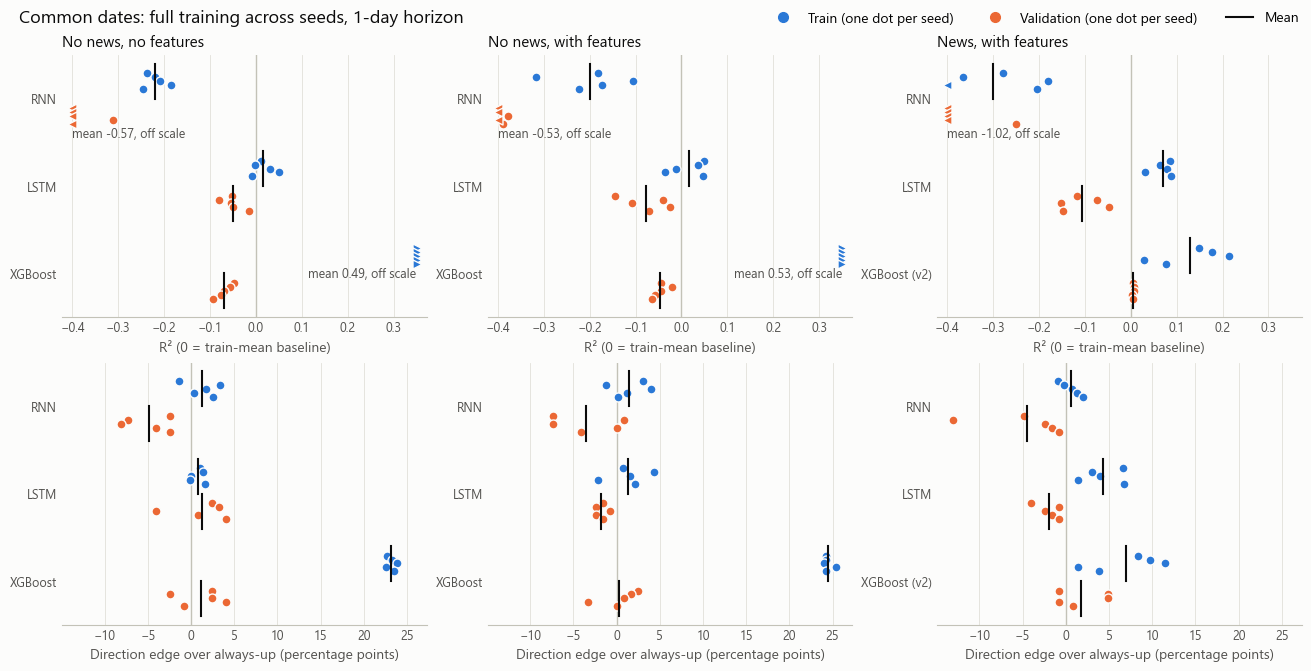

In [8]:
plot_seed_results(
    pd.read_csv(RESULTS_DIR / "phase1_common_dates_seed_metrics.csv"),
    title="Common dates: full training across seeds, 1-day horizon",
)

### Common dates: summary table

In [9]:
pd.read_csv(RESULTS_DIR / "phase1_common_dates_seed_summary.csv").drop(columns=["horizon", "seeds"])

,track,model,split,r2_mean,r2_std,correlation_mean,correlation_std,spread_ratio_mean,spread_ratio_std,directional_accuracy_mean,directional_accuracy_std,always_up_accuracy,share_beating_baseline
0,no_news_no_feature_engineering,RNN,train,-0.2199,0.0242,0.1794,0.0150,0.6570,0.0337,0.5573,0.0188,0.5442,0.0000
1,no_news_no_feature_engineering,RNN,validation,-0.5727,0.2163,-0.0378,0.0655,0.6969,0.0992,0.5041,0.0270,0.5528,0.0000
2,no_news_no_feature_engineering,LSTM,train,0.0161,0.0235,0.1933,0.0309,0.2833,0.0451,0.5521,0.0082,0.5442,0.6000
3,no_news_no_feature_engineering,LSTM,validation,-0.0503,0.0228,0.0700,0.0713,0.2765,0.0323,0.5659,0.0323,0.5528,0.0000
4,no_news_no_feature_engineering,XGBoost,train,0.4922,0.0027,0.8199,0.0029,0.3957,0.0026,0.7761,0.0053,0.5442,1.0000
5,no_news_no_feature_engineering,XGBoost,validation,-0.0686,0.0174,0.0334,0.0280,0.2837,0.0092,0.5642,0.0267,0.5528,0.0000
6,no_news_with_feature_engineering,RNN,train,-0.2004,0.0775,0.2014,0.0438,0.6807,0.0569,0.5586,0.0209,0.5442,0.0000
7,no_news_with_feature_engineering,RNN,validation,-0.5343,0.1680,0.0214,0.0743,0.7430,0.1693,0.5171,0.0388,0.5528,0.0000
8,no_news_with_feature_engineering,LSTM,train,0.0171,0.0387,0.2060,0.0555,0.2598,0.0326,0.5573,0.0236,0.5442,0.6000
9,no_news_with_feature_engineering,LSTM,validation,-0.0781,0.0488,0.0367,0.0716,0.2368,0.0628,0.5350,0.0068,0.5528,0.0000


### Common dates: fit on training data, no news, no features

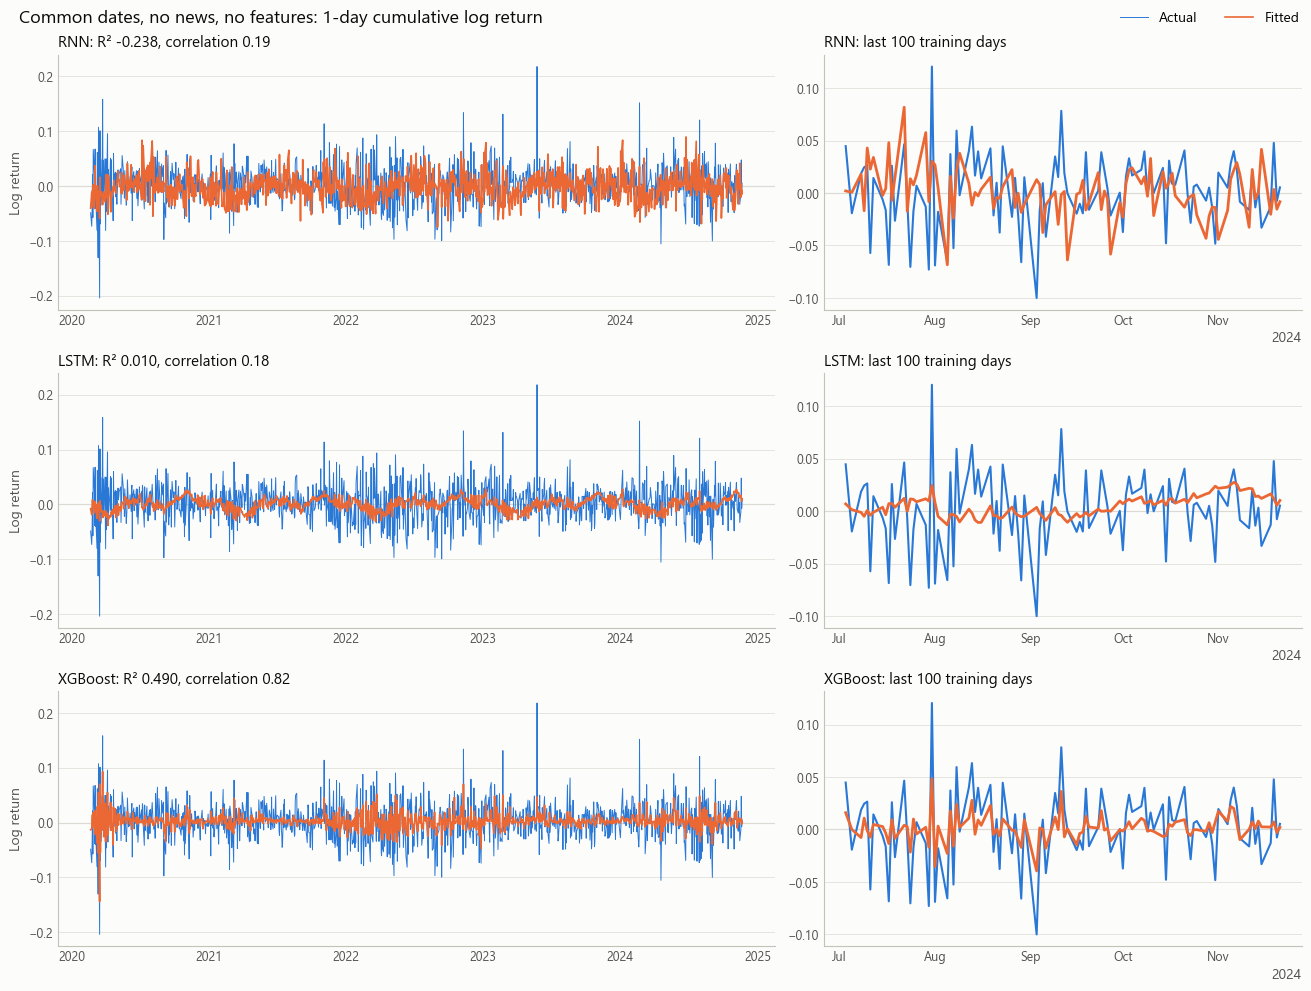

In [10]:
plot_saved_training_fit(
    saved_predictions("phase1_common_dates", NO_NEWS_NO_FEATURES),
    title="Common dates, no news, no features",
);

### Common dates: fit on training data, no news, with features

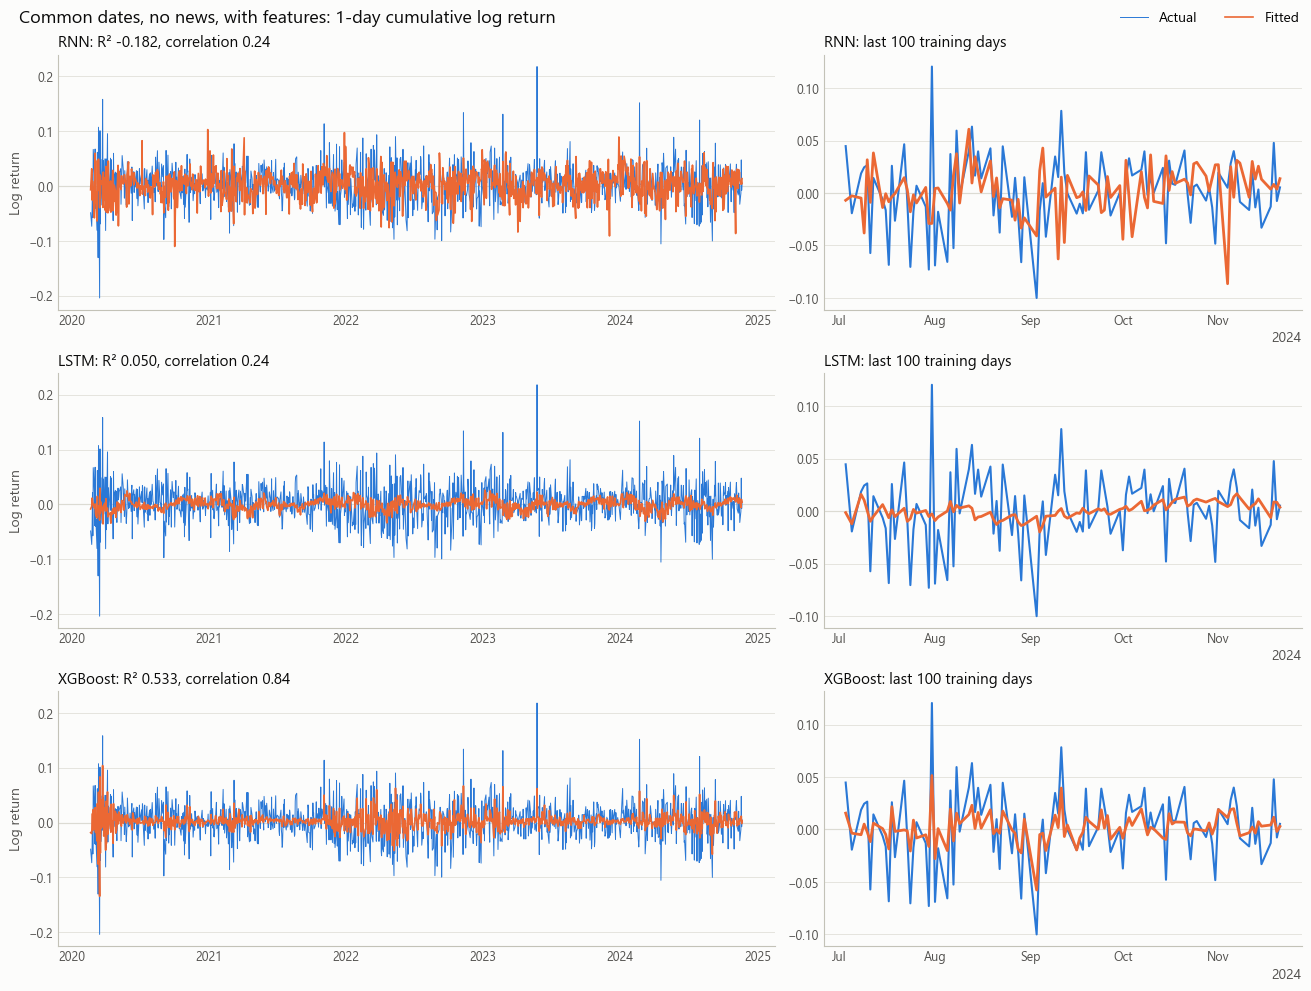

In [11]:
plot_saved_training_fit(
    saved_predictions("phase1_common_dates", NO_NEWS_WITH_FEATURES),
    title="Common dates, no news, with features",
);

### Common dates: fit on training data, news, with features

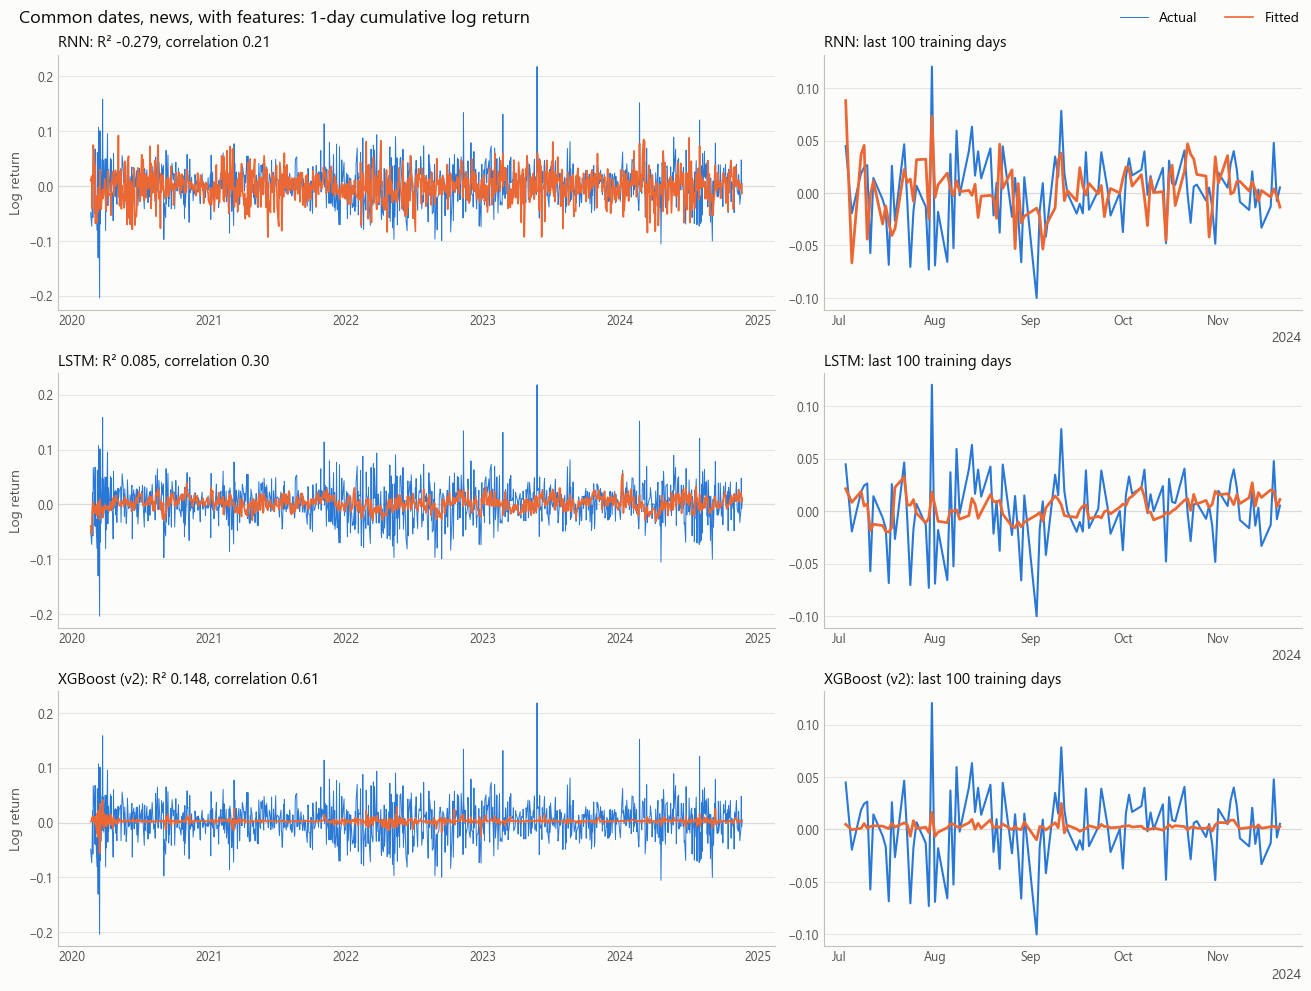

In [12]:
plot_saved_training_fit(
    saved_predictions("phase1_common_dates", NEWS_WITH_FEATURES),
    title="Common dates, news, with features",
);

### Common dates: fit on validation data, no news, no features

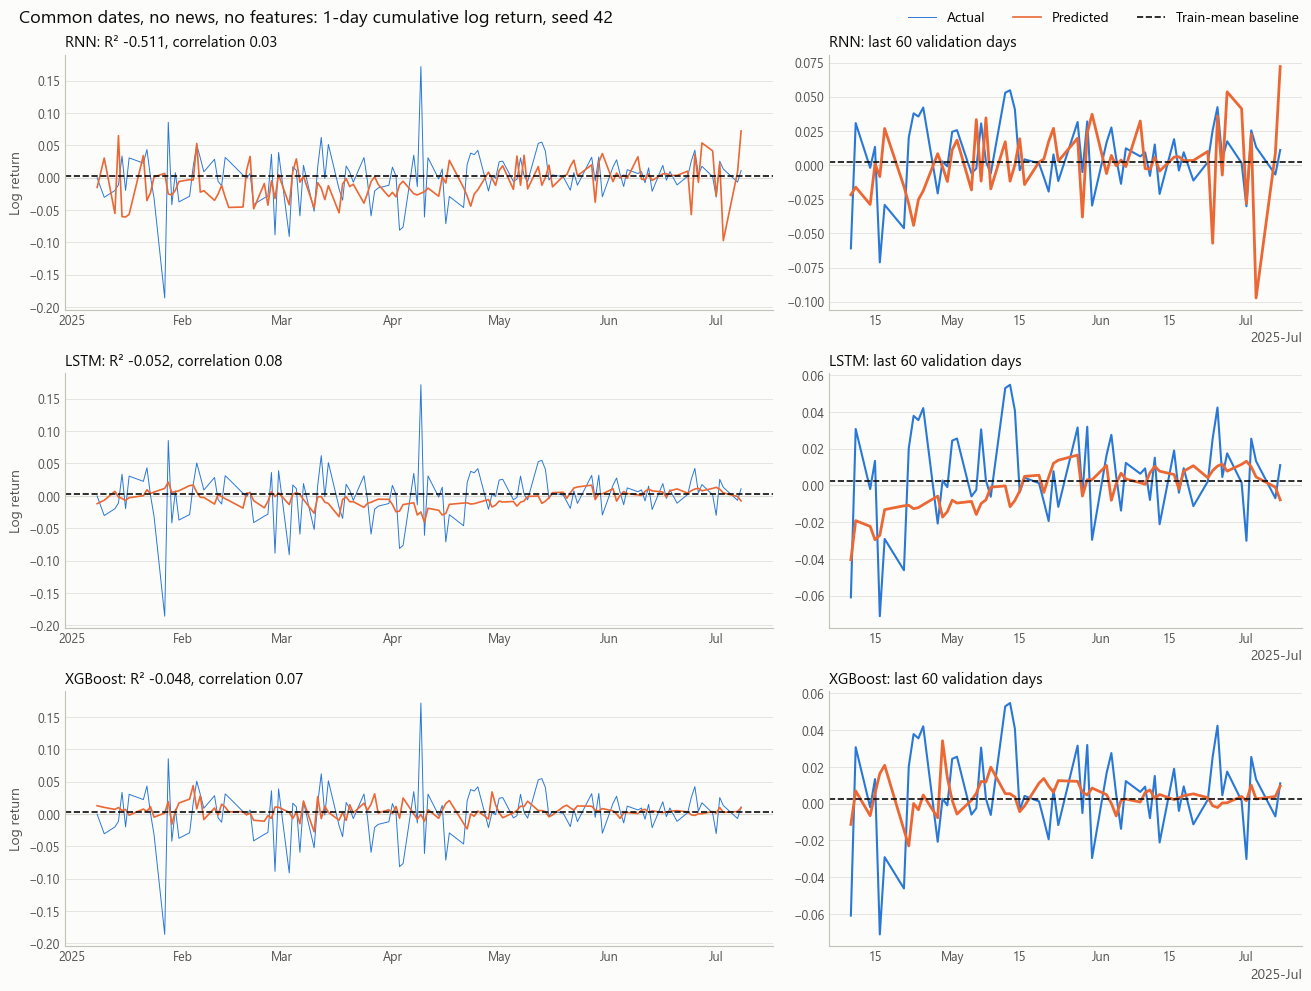

In [13]:
plot_validation_fit(
    saved_predictions("phase1_common_dates", NO_NEWS_NO_FEATURES),
    title="Common dates, no news, no features",
);

### Common dates: fit on validation data, no news, with features

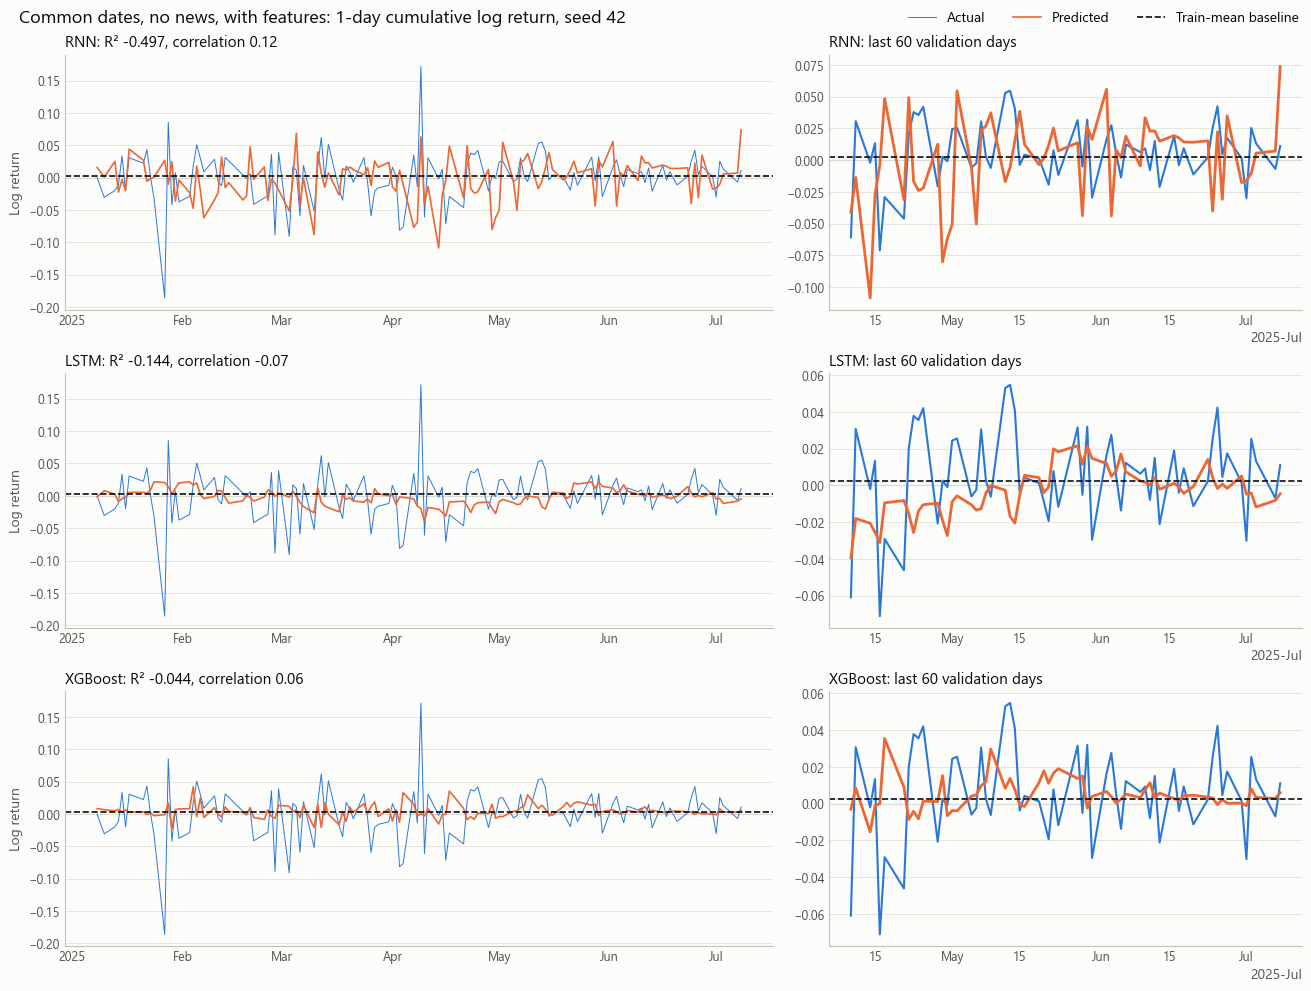

In [14]:
plot_validation_fit(
    saved_predictions("phase1_common_dates", NO_NEWS_WITH_FEATURES),
    title="Common dates, no news, with features",
);

### Common dates: fit on validation data, news, with features

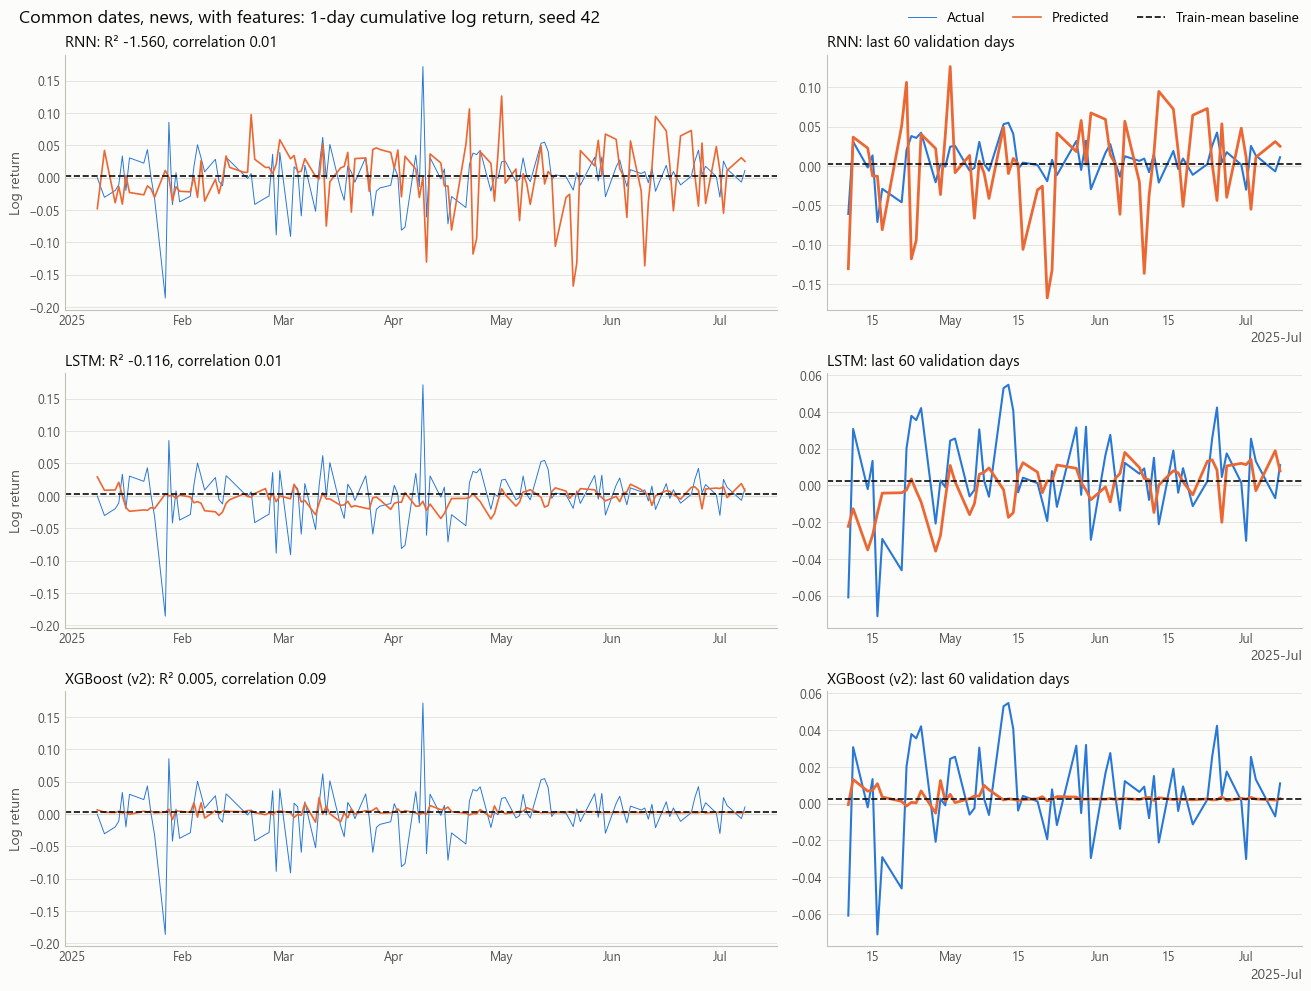

In [15]:
plot_validation_fit(
    saved_predictions("phase1_common_dates", NEWS_WITH_FEATURES),
    title="Common dates, news, with features",
);

## Phase 2: common dates with standardization

The only change from the section above is standardization, fit on training rows only. Inputs are standardized except the cyclical date features, which are already between -1 and 1. The target is standardized for training, and predictions are converted back to log returns before scoring, so the metrics stay comparable.

XGBoost is a control. Trees depend on the order of values rather than their size, so its results should barely move. If they do, suspect a bug.

The next cell trains the models and saves the results. The chart cells after it read those files, so they can be rerun on their own.

In [16]:
standardized_overfit, standardized_results, standardized_metrics = run_phase(
    "phase2_common_dates_standardized", common_dates=True, standardize=True
)

### Common dates, standardized: can each model memorize 100 windows?

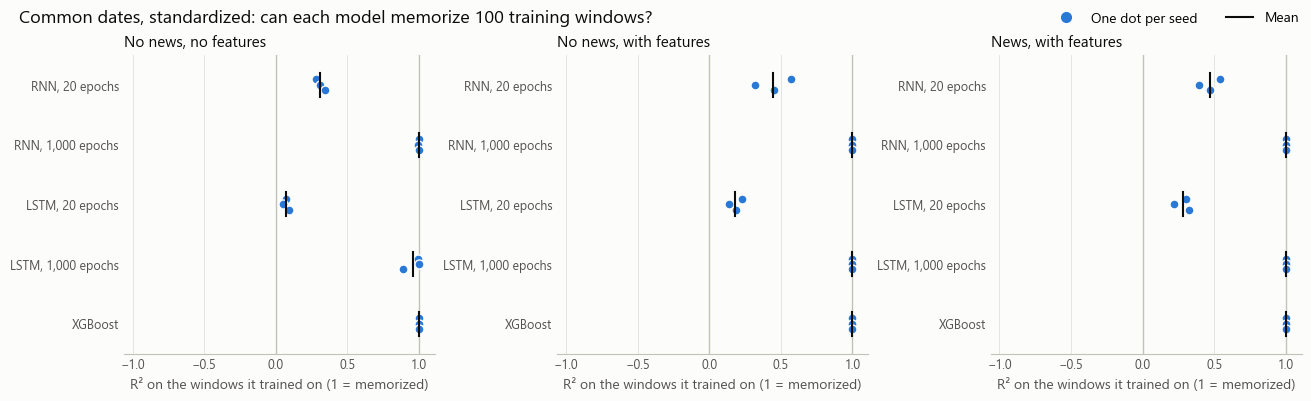

In [17]:
plot_overfit_results(
    pd.read_csv(RESULTS_DIR / "phase2_common_dates_standardized_overfit.csv"),
    title="Common dates, standardized: can each model memorize 100 training windows?",
)

### Common dates, standardized: full training across seeds

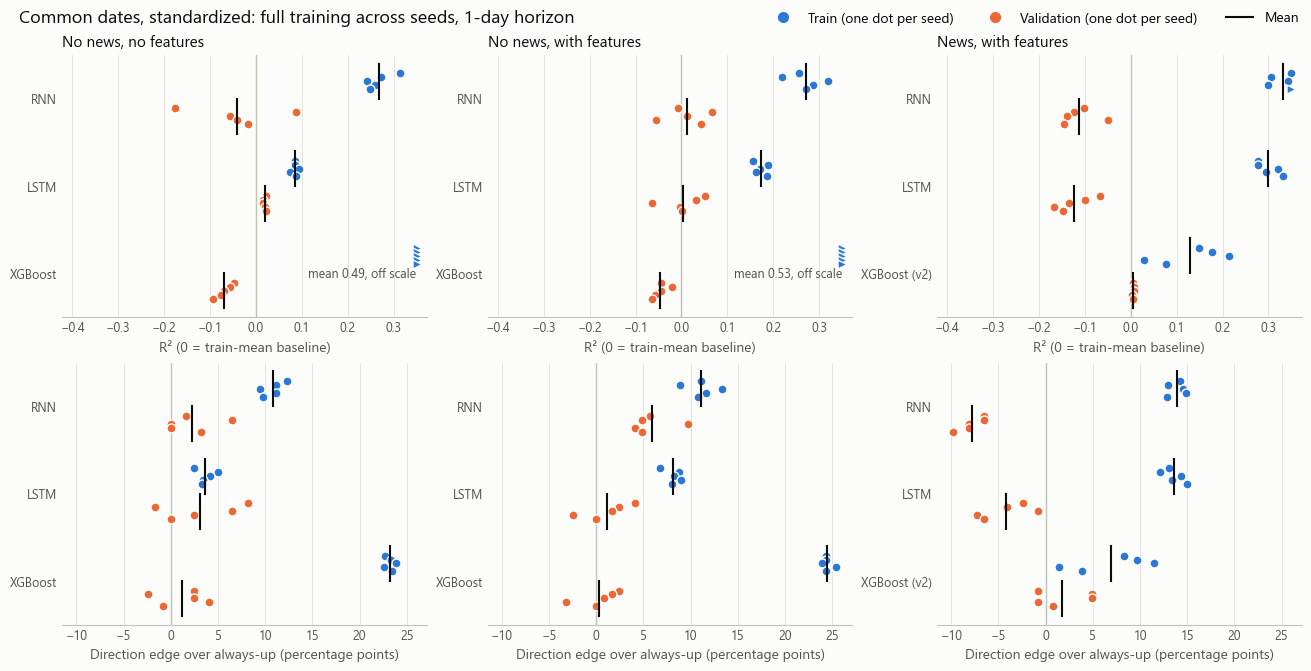

In [18]:
plot_seed_results(
    pd.read_csv(RESULTS_DIR / "phase2_common_dates_standardized_seed_metrics.csv"),
    title="Common dates, standardized: full training across seeds, 1-day horizon",
)

### Common dates, standardized: summary table

In [19]:
pd.read_csv(RESULTS_DIR / "phase2_common_dates_standardized_seed_summary.csv").drop(columns=["horizon", "seeds"])

,track,model,split,r2_mean,r2_std,correlation_mean,correlation_std,spread_ratio_mean,spread_ratio_std,directional_accuracy_mean,directional_accuracy_std,always_up_accuracy,share_beating_baseline
0,no_news_no_feature_engineering,RNN,train,0.2672,0.0287,0.5412,0.0245,0.3822,0.0342,0.6521,0.0119,0.5442,1.0000
1,no_news_no_feature_engineering,RNN,validation,-0.0412,0.0944,0.1440,0.1127,0.3579,0.0517,0.5756,0.0272,0.5528,0.2000
2,no_news_no_feature_engineering,LSTM,train,0.0851,0.0075,0.3113,0.0191,0.2066,0.0174,0.5810,0.0097,0.5442,1.0000
3,no_news_no_feature_engineering,LSTM,validation,0.0192,0.0034,0.1803,0.0228,0.2475,0.0200,0.5837,0.0416,0.5528,1.0000
4,no_news_no_feature_engineering,XGBoost,train,0.4922,0.0027,0.8199,0.0029,0.3956,0.0026,0.7761,0.0053,0.5442,1.0000
5,no_news_no_feature_engineering,XGBoost,validation,-0.0686,0.0174,0.0334,0.0280,0.2837,0.0092,0.5642,0.0267,0.5528,0.0000
6,no_news_with_feature_engineering,RNN,train,0.2707,0.0367,0.5438,0.0347,0.3862,0.0336,0.6554,0.0159,0.5442,1.0000
7,no_news_with_feature_engineering,RNN,validation,0.0117,0.0469,0.2096,0.0534,0.3637,0.0344,0.6114,0.0226,0.5528,0.6000
8,no_news_with_feature_engineering,LSTM,train,0.1728,0.0139,0.4430,0.0150,0.2922,0.0229,0.6257,0.0088,0.5442,1.0000
9,no_news_with_feature_engineering,LSTM,validation,0.0029,0.0435,0.2473,0.0544,0.3510,0.0339,0.5642,0.0248,0.5528,0.6000


### Common dates, standardized: fit on training data, no news, no features

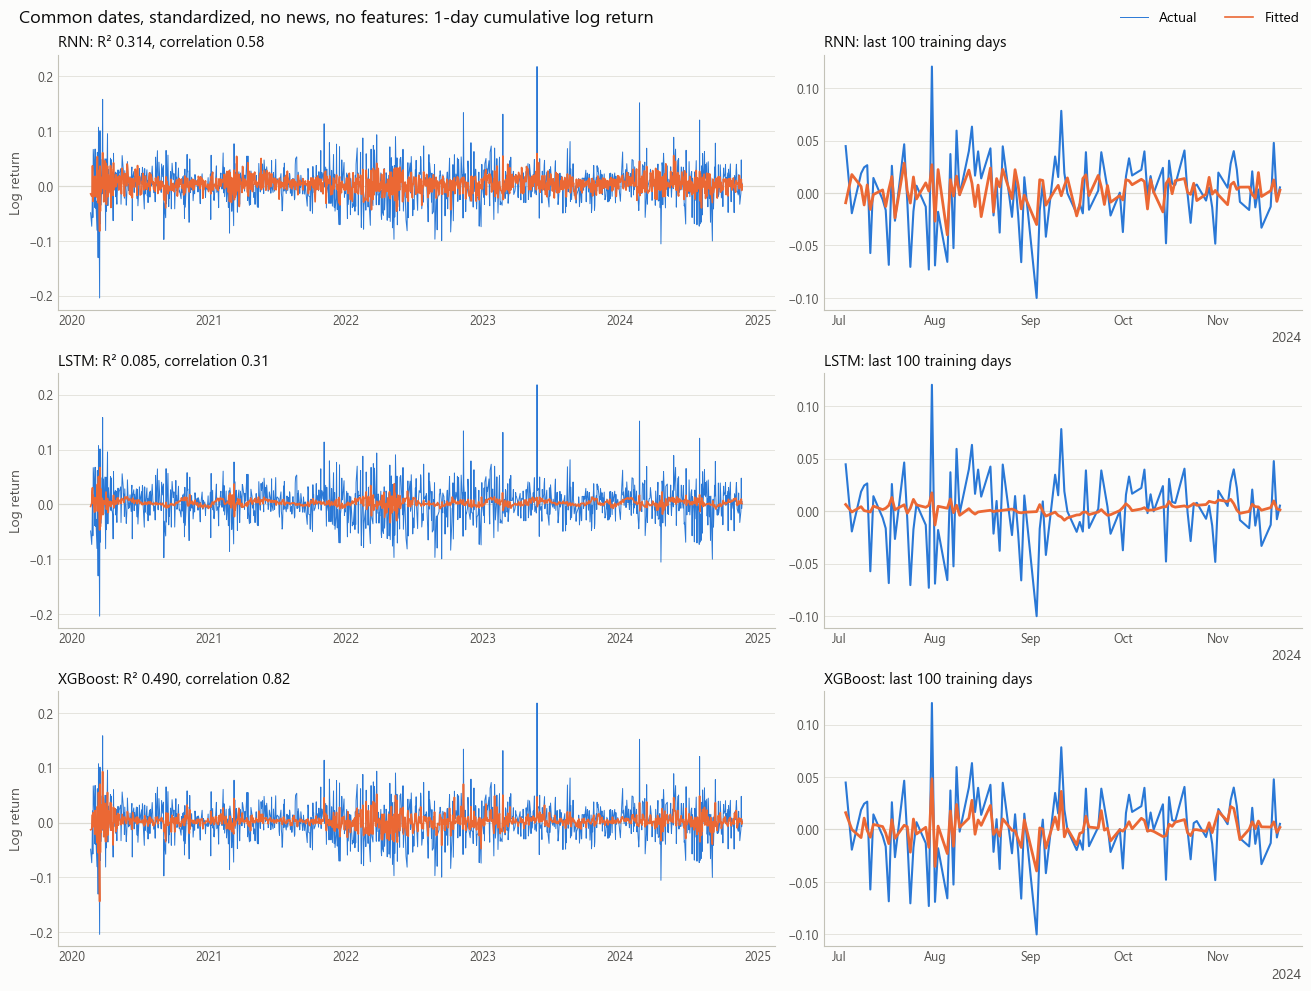

In [20]:
plot_saved_training_fit(
    saved_predictions("phase2_common_dates_standardized", NO_NEWS_NO_FEATURES),
    title="Common dates, standardized, no news, no features",
);

### Common dates, standardized: fit on training data, no news, with features

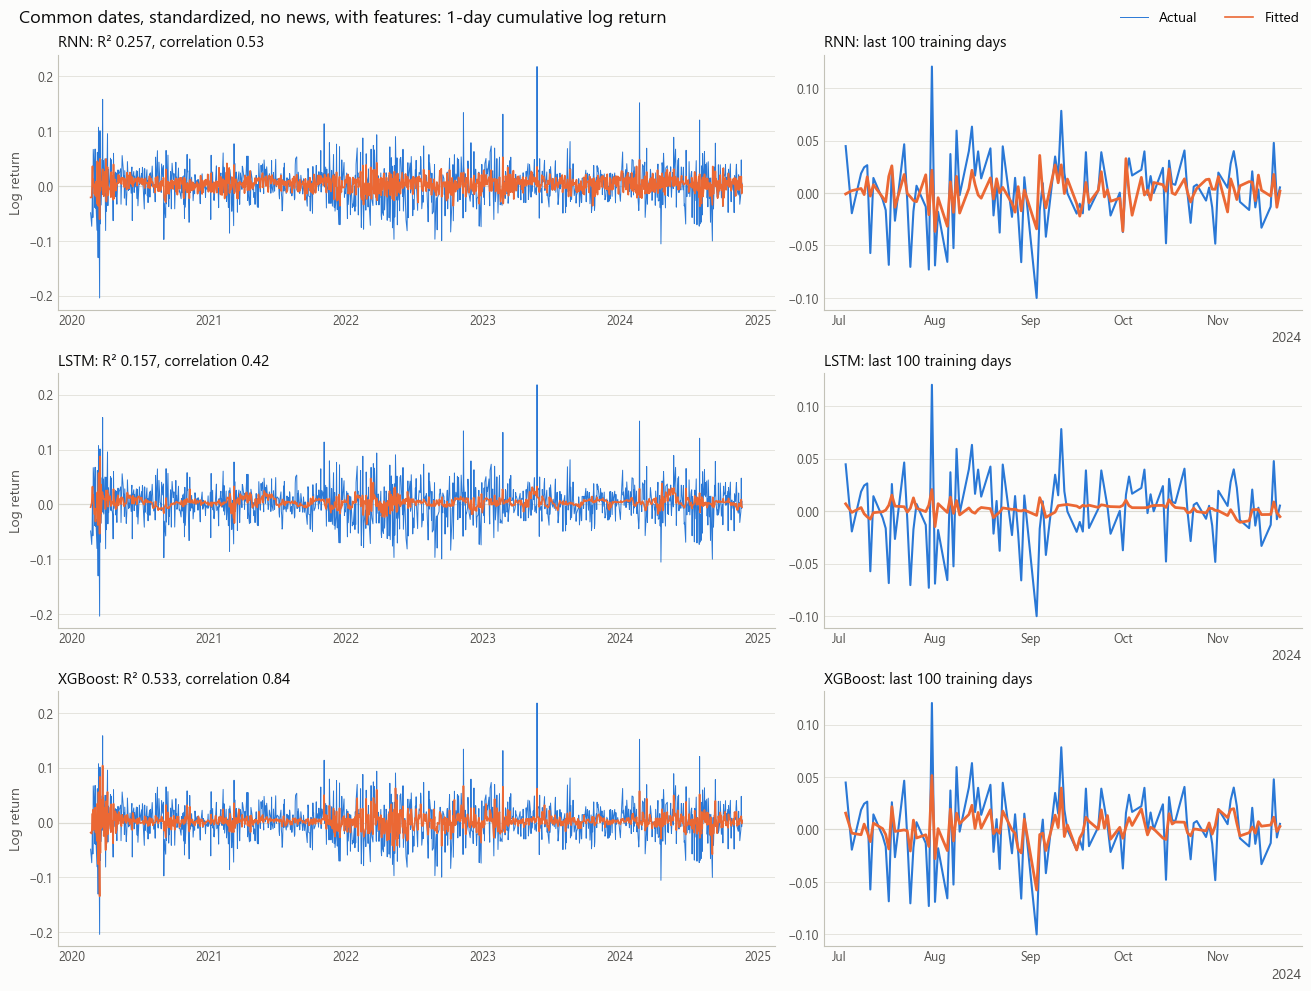

In [21]:
plot_saved_training_fit(
    saved_predictions("phase2_common_dates_standardized", NO_NEWS_WITH_FEATURES),
    title="Common dates, standardized, no news, with features",
);

### Common dates, standardized: fit on training data, news, with features

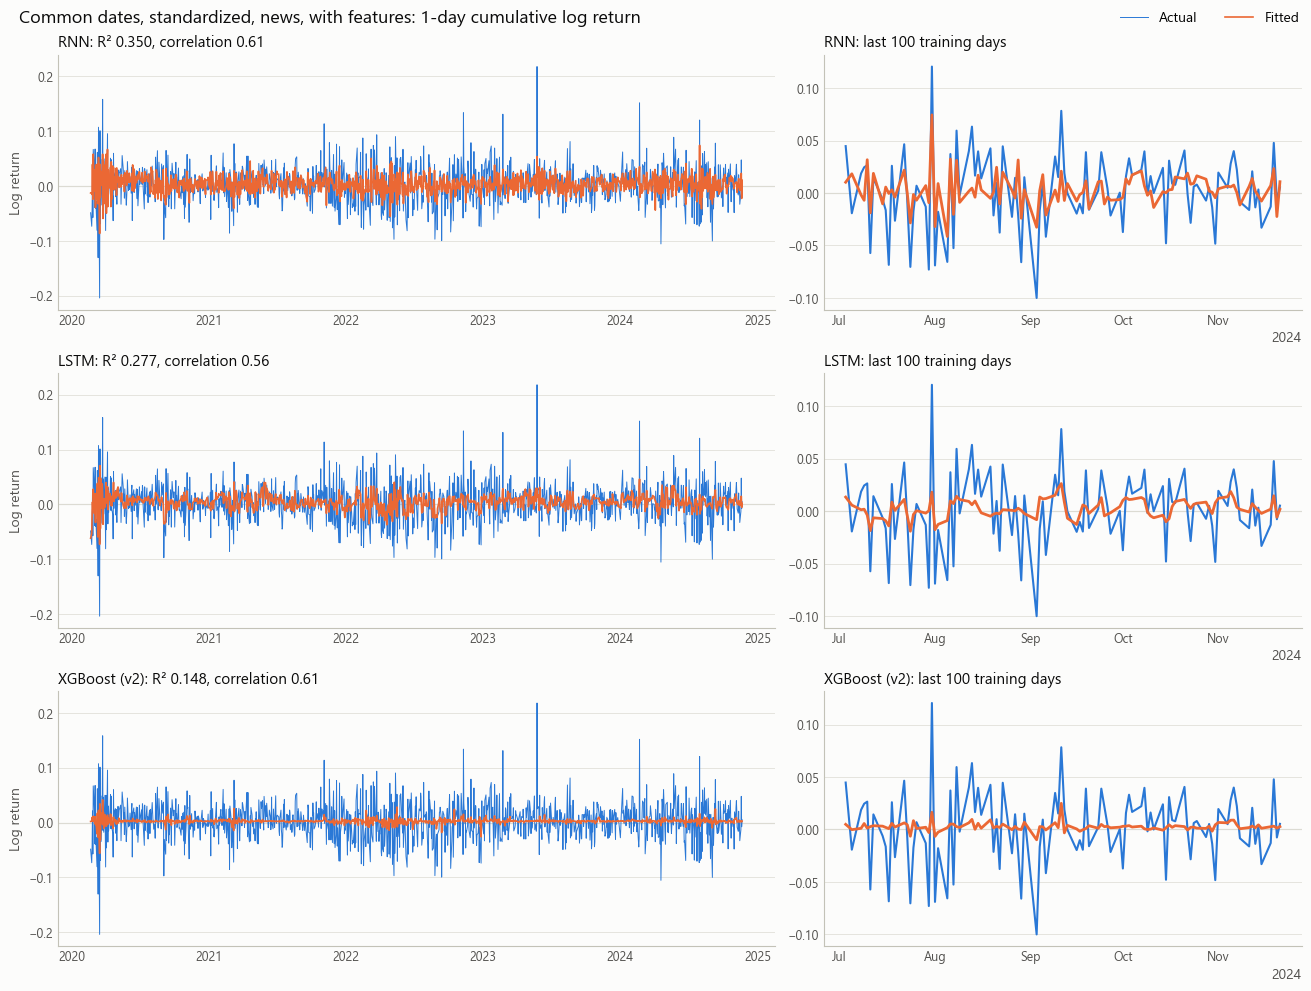

In [22]:
plot_saved_training_fit(
    saved_predictions("phase2_common_dates_standardized", NEWS_WITH_FEATURES),
    title="Common dates, standardized, news, with features",
);

### Common dates, standardized: fit on validation data, no news, no features

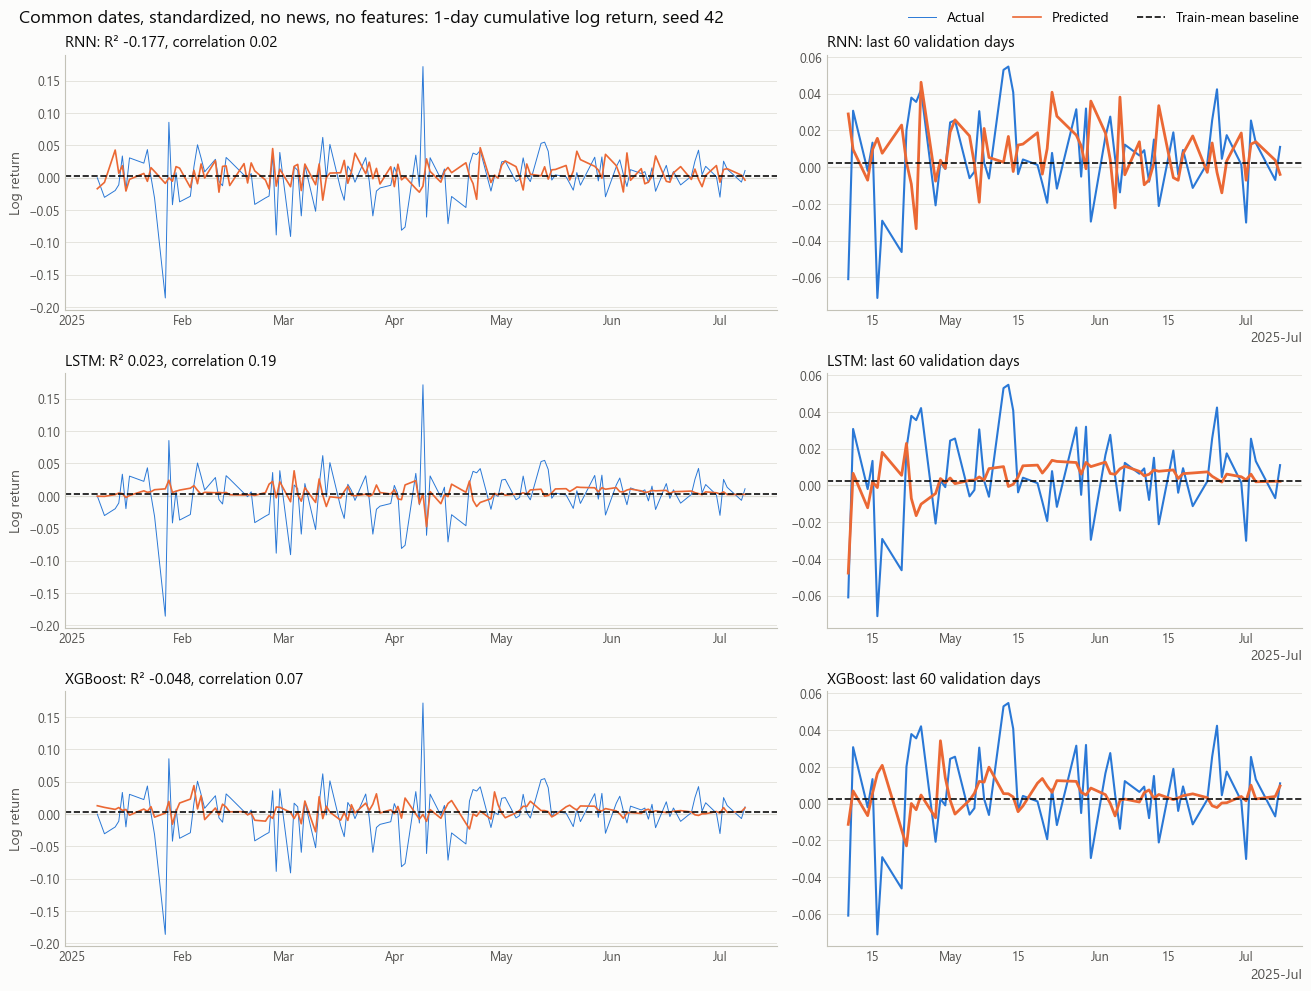

In [23]:
plot_validation_fit(
    saved_predictions("phase2_common_dates_standardized", NO_NEWS_NO_FEATURES),
    title="Common dates, standardized, no news, no features",
);

### Common dates, standardized: fit on validation data, no news, with features

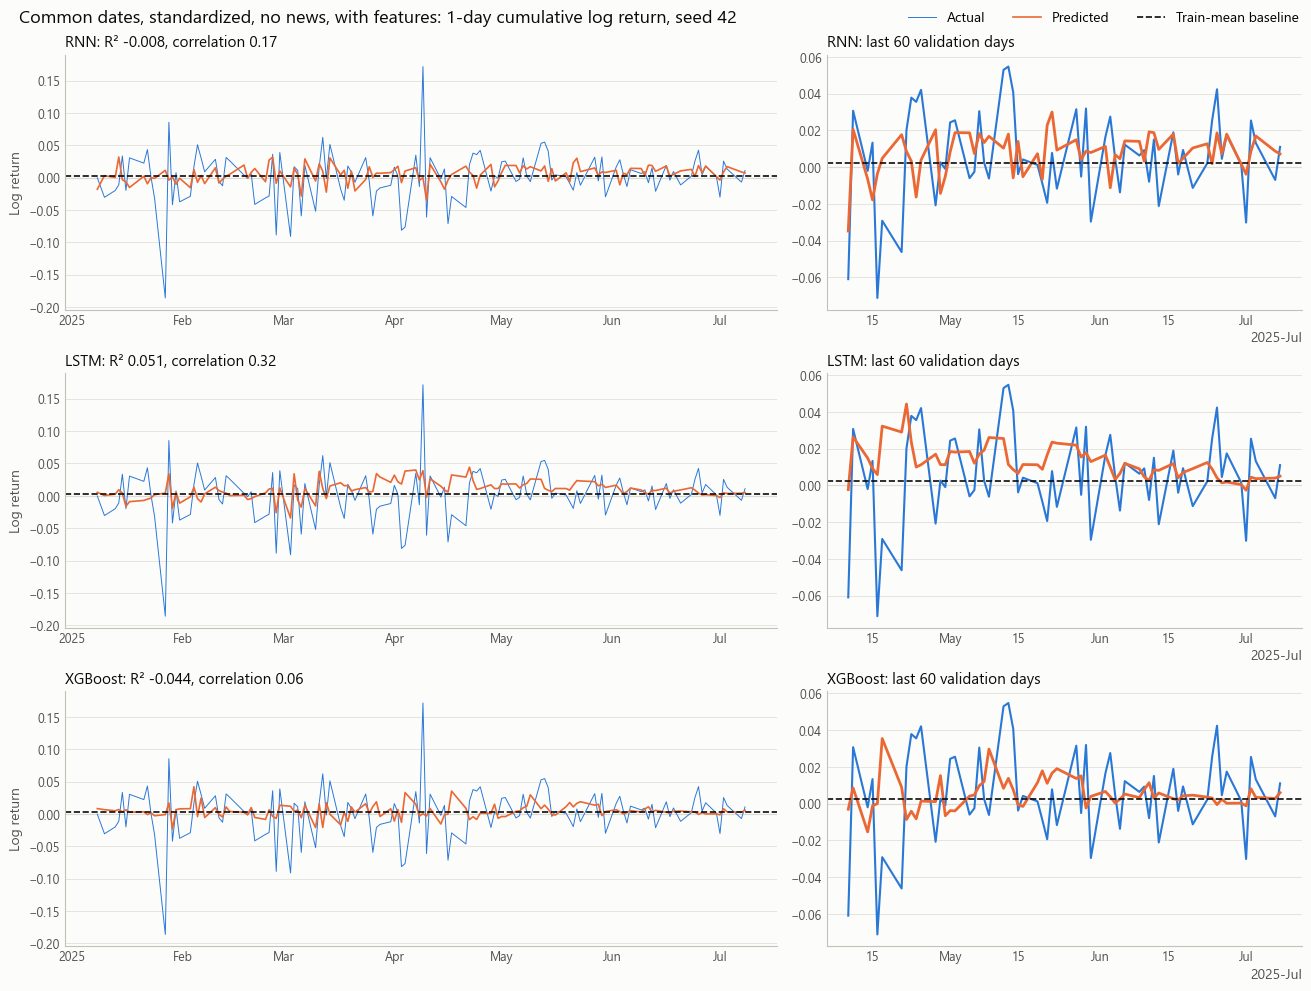

In [24]:
plot_validation_fit(
    saved_predictions("phase2_common_dates_standardized", NO_NEWS_WITH_FEATURES),
    title="Common dates, standardized, no news, with features",
);

### Common dates, standardized: fit on validation data, news, with features

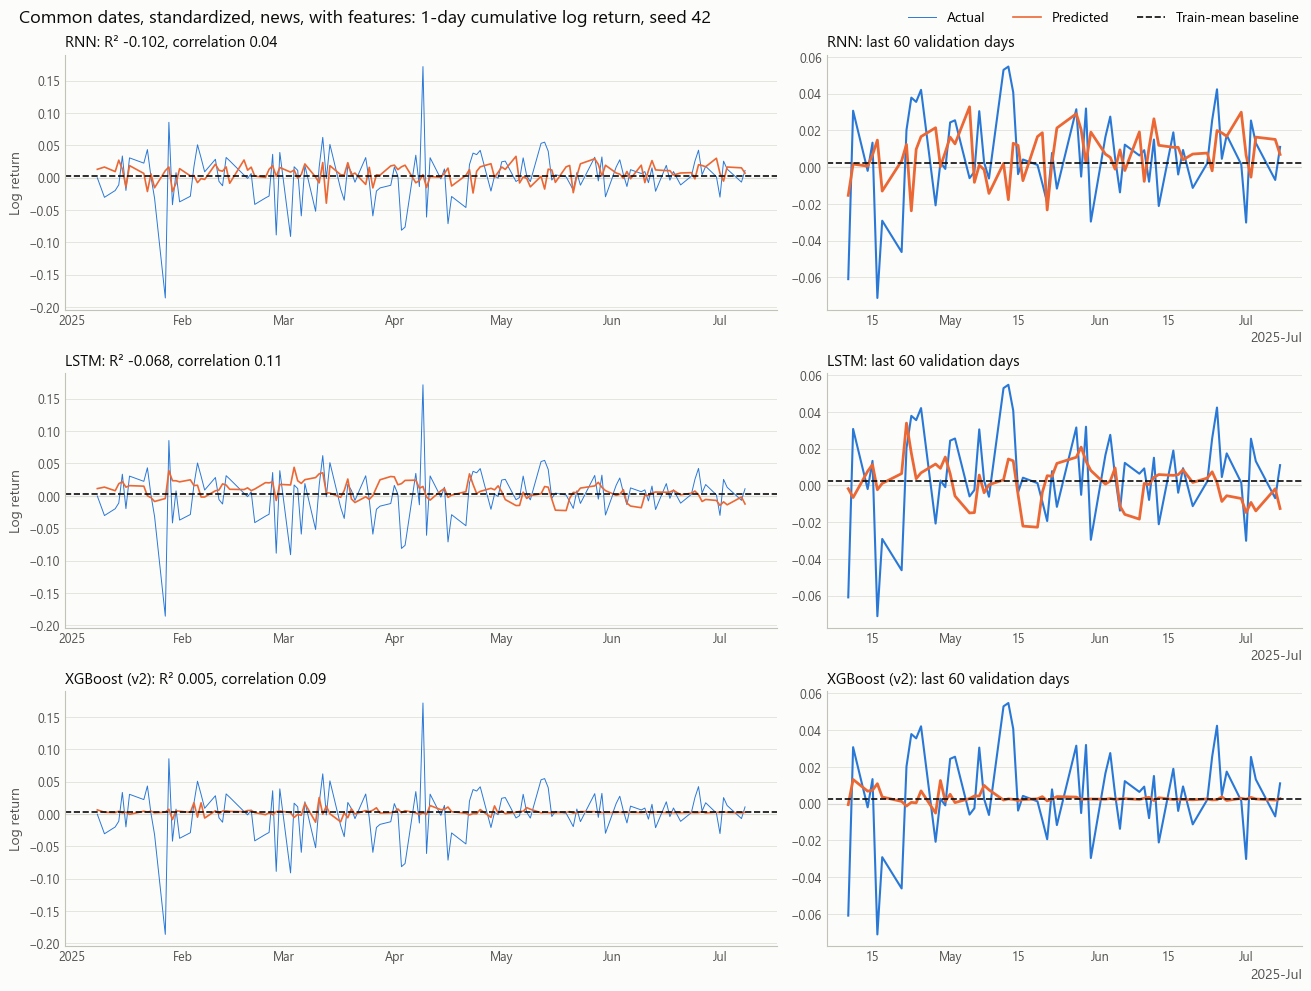

In [25]:
plot_validation_fit(
    saved_predictions("phase2_common_dates_standardized", NEWS_WITH_FEATURES),
    title="Common dates, standardized, news, with features",
);

## Comparing the runs

Means across seeds, read from the saved results. The original run used each no-news track's full history, so only the last two columns share the same dates.

In [26]:
RUNS = {
    "original": "phase1",
    "common dates": "phase1_common_dates",
    "common + standardized": "phase2_common_dates_standardized",
}
RUN_ORDER = list(RUNS)

runs = pd.concat(pd.read_csv(RESULTS_DIR / f"{prefix}_seed_metrics.csv").assign(run=run) for run, prefix in RUNS.items())
runs["direction_edge"] = 100 * (runs["directional_accuracy"] - runs["always_up_accuracy"])
validation = runs[runs["split"] == "validation"]

for metric in ("r2", "direction_edge"):
    print(metric, "on validation")
    display(validation.pivot_table(index=["track", "model"], columns="run", values=metric, sort=False)[RUN_ORDER])

# MSE values are tiny, so they're shown multiplied by 10,000.
scaled_mse = validation.assign(mse=validation["mse"] * 1e4, baseline_mse=validation["baseline_mse"] * 1e4)
print("MSE × 10,000 on validation, next to the train-mean baseline")
display(
    scaled_mse.pivot_table(index=["track", "model"], columns="run", values=["baseline_mse", "mse"], sort=False)
    .swaplevel(axis=1)[RUN_ORDER]
)

memorize = pd.concat(pd.read_csv(RESULTS_DIR / f"{prefix}_overfit.csv").assign(run=run) for run, prefix in RUNS.items())
memorize = memorize[memorize["epochs"].notna()].astype({"epochs": int})
print("R² on the 100 memorized windows")
display(memorize.pivot_table(index=["track", "model", "epochs"], columns="run", values="r2", sort=False)[RUN_ORDER])

r2 on validation


run                                            original  common dates  common + standardized
track                            model                                                      
no_news_no_feature_engineering   RNN            -0.1436       -0.5727                -0.0412
                                 LSTM           -0.0262       -0.0503                 0.0192
                                 XGBoost        -0.0225       -0.0686                -0.0686
no_news_with_feature_engineering RNN            -0.2323       -0.5343                 0.0117
                                 LSTM           -0.0338       -0.0781                 0.0029
                                 XGBoost        -0.0114       -0.0461                -0.0461
news_with_feature_engineering    RNN            -1.0158       -1.0158                -0.1119
                                 LSTM           -0.1073       -0.1073                -0.1232
                                 XGBoost (v2)    0.0055        0.0055                 0.0055

direction_edge on validation


run                                            original  common dates  common + standardized
track                            model                                                      
no_news_no_feature_engineering   RNN            -2.8264       -4.8780                 2.2764
                                 LSTM           -3.1336        1.3008                 3.0894
                                 XGBoost        -3.0722        1.1382                 1.1382
no_news_with_feature_engineering RNN            -1.8519       -3.5772                 5.8537
                                 LSTM           -1.4198       -1.7886                 1.1382
                                 XGBoost        -2.7778        0.3252                 0.3252
news_with_feature_engineering    RNN            -4.5528       -4.5528                -7.8049
                                 LSTM           -1.9512       -1.9512                -4.2276
                                 XGBoost (v2)    1.7886        1.7886                 1.7886

MSE × 10,000 on validation, next to the train-mean baseline


run                                               original         common dates         common + standardized        
                                              baseline_mse     mse baseline_mse     mse          baseline_mse     mse
track                            model                                                                               
no_news_no_feature_engineering   RNN               11.7901 13.4785      15.1226 23.7533               15.1226 15.7260
                                 LSTM              11.7901 12.0950      15.1226 15.8634               15.1226 14.8134
                                 XGBoost           11.7901 12.0513      15.1226 16.1398               15.1226 16.1398
no_news_with_feature_engineering RNN               11.7473 14.4739      15.1226 23.1730               15.1226 14.9271
                                 LSTM              11.7473 12.1415      15.1226 16.2825               15.1226 15.0591
                                 XGBoost           11.7473 11.8788      15.1226 15.7996               15.1226 15.7996
news_with_feature_engineering    RNN               15.1226 30.4457      15.1226 30.4457               15.1226 16.7937
                                 LSTM              15.1226 16.7240      15.1226 16.7240               15.1226 16.9644
                                 XGBoost (v2)      15.1226 15.0209      15.1226 15.0209               15.1226 15.0209

R² on the 100 memorized windows


run                                            original  common dates  common + standardized
track                            model epochs                                               
no_news_no_feature_engineering   RNN   20       -3.6675       -1.6367                 0.3116
                                       1000      0.9114        0.9706                 0.9990
                                 LSTM  20        0.0209        0.0257                 0.0706
                                       1000      0.7604        0.8997                 0.9611
no_news_with_feature_engineering RNN   20       -4.4731       -1.2788                 0.4476
                                       1000      0.9773        0.8353                 1.0000
                                 LSTM  20        0.0230        0.0720                 0.1834
                                       1000      0.8064        0.8854                 0.9980
news_with_feature_engineering    RNN   20       -2.8862       -2.8862                 0.4706
                                       1000      0.9998        0.9998                 1.0000
                                 LSTM  20        0.1603        0.1603                 0.2830
                                       1000      0.9977        0.9977                 0.9998

## Walk-forward evaluation of the Phase 2 setup

The Phase 2 setup, before changing any models: common dates and standardization, at the 1-day horizon. There are 8 rounds, starting from 600 known days and scoring about 100 days each, so 781 days are scored. Each round refits the scaling, models and baseline. Only rows before the locked test split are loaded.

A round's last 10% of known days are kept for early stopping, rather than scored days, so XGBoost (v2) has no advantage from them here. All models train on the other 90%.

The next cell trains the models and saves each fit, so it continues where it stopped if interrupted. If every fit is already saved, it finishes quickly.

In [27]:
from benchmarking.result_plots import plot_walk_forward_intervals, plot_walk_forward_rounds
from benchmarking.walk_forward import (
    WalkForwardConfig,
    run_walk_forward,
    score_walk_forward,
    walk_forward_intervals,
)

WALK_FORWARD_PATH = RESULTS_DIR / "walk_forward_phase2_predictions.csv"

for track in TRACKS:
    run_walk_forward(WalkForwardConfig(track=track, seeds=(42, 43, 44, 45, 46)), WALK_FORWARD_PATH)

walk_forward = pd.read_csv(WALK_FORWARD_PATH)

### Walk-forward: results with confidence intervals

`oos_r2` is R² against the train-mean baseline. An interval that includes 0 can't be told apart from the baseline. MSE values are shown multiplied by 10,000.

In [28]:
intervals = walk_forward_intervals(walk_forward)
intervals.to_csv(RESULTS_DIR / "walk_forward_phase2_intervals.csv", index=False)
intervals.assign(mse=intervals["mse"] * 1e4, baseline_mse=intervals["baseline_mse"] * 1e4).drop(columns="horizon")

,track,model,days,mse,baseline_mse,oos_r2,oos_r2_lower,oos_r2_upper,directional_accuracy,always_up_accuracy,direction_edge,direction_edge_lower,direction_edge_upper
0,no_news_no_feature_engineering,RNN,781,12.4375,11.5200,-0.0796,-0.1343,-0.0366,0.5316,0.5493,-1.7670,-5.6344,1.8956
1,no_news_no_feature_engineering,LSTM,781,12.0258,11.5200,-0.0439,-0.0981,0.0011,0.5060,0.5493,-4.3278,-8.6556,-0.2817
2,no_news_no_feature_engineering,XGBoost,781,12.5259,11.5200,-0.0873,-0.1414,-0.0338,0.5132,0.5493,-3.6108,-7.6831,0.5890
3,no_news_with_feature_engineering,RNN,781,12.8291,11.5200,-0.1136,-0.1946,-0.0472,0.5181,0.5493,-3.1242,-6.7093,0.0775
4,no_news_with_feature_engineering,LSTM,781,14.5138,11.5200,-0.2599,-0.4905,-0.0921,0.5104,0.5493,-3.8924,-8.3745,-0.1274
5,no_news_with_feature_engineering,XGBoost,781,12.5629,11.5200,-0.0905,-0.1537,-0.0329,0.5227,0.5493,-2.6633,-7.2247,1.6396
6,news_with_feature_engineering,RNN,781,13.0048,11.5200,-0.1289,-0.1854,-0.0869,0.4976,0.5493,-5.1729,-8.7330,-1.7926
7,news_with_feature_engineering,LSTM,781,13.7903,11.5200,-0.1971,-0.2787,-0.1315,0.5088,0.5493,-4.0461,-8.2714,-0.3841
8,news_with_feature_engineering,XGBoost (v2),781,11.8354,11.5200,-0.0274,-0.0469,-0.0101,0.5193,0.5493,-2.9962,-5.6607,-0.6914


### Walk-forward: all scored days

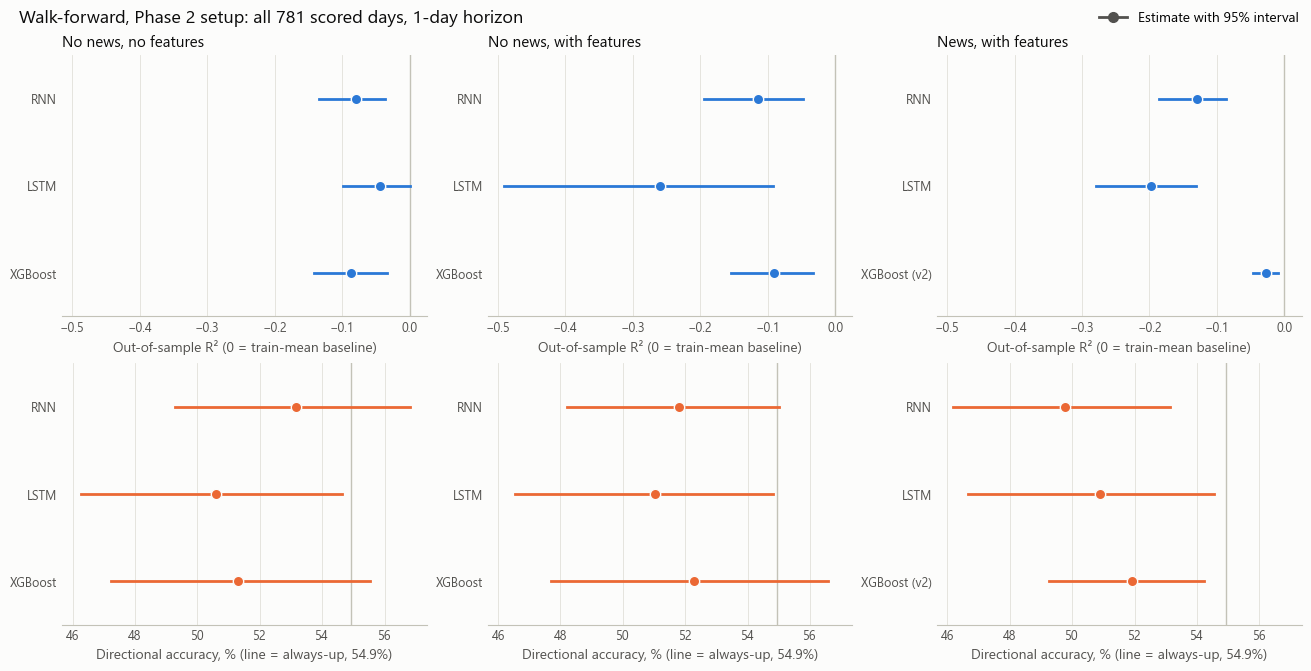

In [29]:
plot_walk_forward_intervals(intervals, title="Walk-forward, Phase 2 setup: all 781 scored days, 1-day horizon")

### Walk-forward: round by round

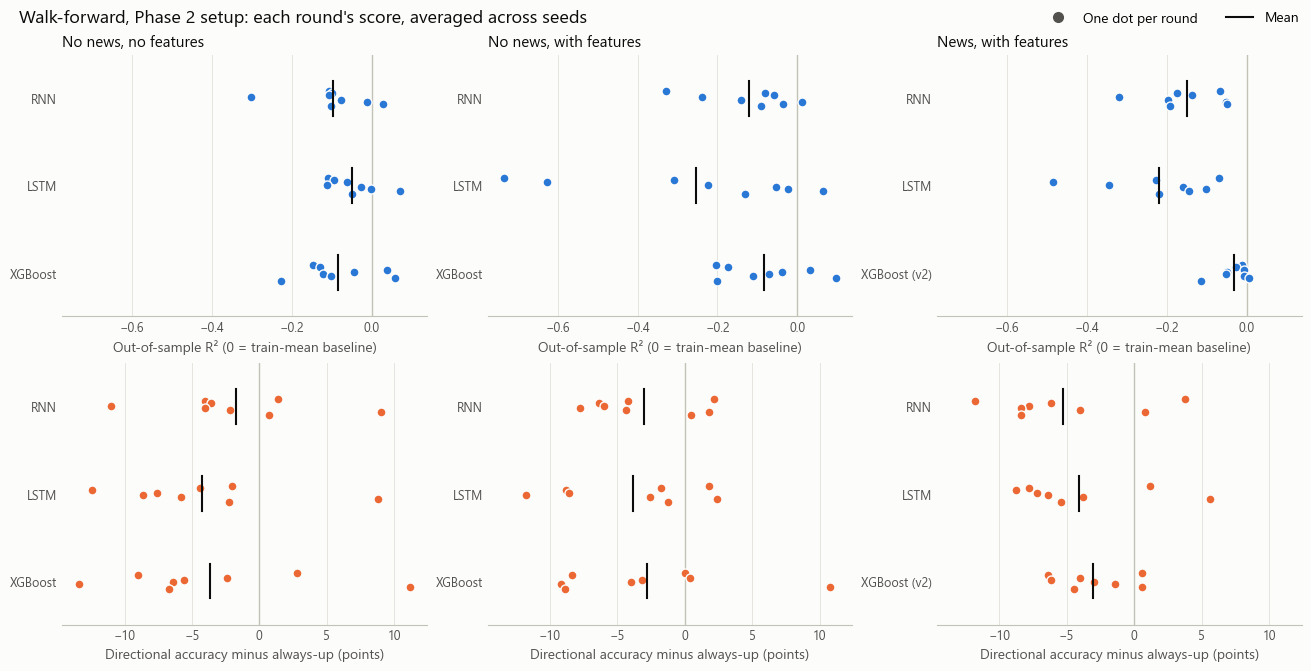

In [30]:
plot_walk_forward_rounds(
    score_walk_forward(walk_forward, by_round=True),
    title="Walk-forward, Phase 2 setup: each round's score, averaged across seeds",
)